# Edge Detection on BSDS500
### U-Net decoder · interchangeable backbones · one comparison table

---

Every backbone listed in `BACKBONES` is trained and tested in turn, and the last cell prints a single test F-score table.
The decoder, Canny input, Canny skip, loss, optimiser, schedule, split and metric are **identical** for every backbone; only the encoder changes.

| | |
|:--|:--|
| **Backbones** | any [timm](https://github.com/huggingface/pytorch-image-models) model with 5 feature stages (`resnet34`, `resnet50`, `mobilenetv2_100`, `efficientnet_b0`, ...) or `vgg16_bn` / `vgg19_bn` (torchvision encoder split at its max-pools) |
| **Data** | official BSDS500 split: train 200 · val 100 (best epoch and threshold) · test 200 (scored once) |
| **Protocol** | 3 seeds per backbone, results saved to `results_<run>.json` |
| **Ablations** | one-line changes: `CANNY_SIGMAS = ()` (RGB only) or `CANNY_SKIP = False` (Canny as input only, no skip to the logits) |

> Runs from earlier sessions are added to the final table if their JSON files are in `/kaggle/input` (add them as a dataset).

In [1]:
import kagglehub

path = kagglehub.dataset_download("dorisdan/bsds500")
print(f"dataset path: {path}")

dataset path: /kaggle/input/datasets/dorisdan/bsds500


## 1 · Setup
*Configuration, hyper-parameters and devices. Different `BACKBONES` without Canny Skip.*

In [2]:
import os, glob, random, time, json

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
from torch.utils.data import Dataset, DataLoader
from scipy.io import loadmat
from skimage.morphology import skeletonize
from tqdm.auto import tqdm

PALETTE = ["#3B6FB6", "#E07B39", "#3FA37A", "#C8553D", "#8E6BBF", "#2A9CB5", "#B8860B", "#D1638A"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.prop_cycle": plt.cycler(color=PALETTE), "axes.grid": True, "grid.alpha": 0.25,
                     "grid.linestyle": "--", "axes.titleweight": "bold", "axes.titlesize": 12, "axes.labelsize": 10})

# any of: resnet34, resnet50, mobilenetv2_100, efficientnet_b0, vgg16_bn
BACKBONES = ('resnet34', 'resnet50', 'mobilenetv2_100', 'efficientnet_b0', 'vgg16_bn')

CANNY_SIGMAS = (0.25, 0.33, 0.5, 0.66, 0.75)
CANNY_SKIP = False
SUFFIX = ("" if CANNY_SIGMAS else "_rgb") + ("" if CANNY_SKIP or not CANNY_SIGMAS else "_noskip")

def run_name(backbone):
    return backbone + SUFFIX

def results_path(backbone):
    return f"/kaggle/working/results_{run_name(backbone)}.json"

DATA_DIR = "/kaggle/input/datasets/dorisdan/bsds500/BSDS500-master/BSDS500/data"

SEEDS = (0, 1, 2, )

EDGE_THRESH = 0.5
PRETRAINED = True
DICE_W = 0.5

EPOCHS = 100
BATCH_SIZE = 32
CROP = 320
LR = 2e-4
WEIGHT_DECAY = 1e-4
VAL_EVERY = 5  
NUM_WORKERS = 4

THRESHOLDS = (0.1, 0.3, 0.5, 0.7, 0.8, 0.9, 0.95, 0.98, 0.99)
N_SHOW = 4

n_gpu = torch.cuda.device_count()
devices = [torch.device(f"cuda:{i}") for i in range(n_gpu)] or [torch.device("cpu")]
device = devices[0]
AMP = device.type == "cuda"
cv2.setNumThreads(1)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

gpu_names = ", ".join(torch.cuda.get_device_name(i) for i in range(n_gpu)) if n_gpu else "CPU"
print(f"runs: {[run_name(b) for b in BACKBONES]} | devices: {len(devices)} ({gpu_names}), mixed precision: {'on' if AMP else 'off'}")

runs: ['resnet34_noskip', 'resnet50_noskip', 'mobilenetv2_100_noskip', 'efficientnet_b0_noskip', 'vgg16_bn_noskip'] | devices: 2 (Tesla T4, Tesla T4), mixed precision: on


## 2 · Data
*Official BSDS500 split*

`images/{train,val,test}` are paired with `groundTruth/{train,val,test}` by file name.

- **Ground truth:** mean of all annotators, thresholded at `EDGE_THRESH`
- **Canny maps:** computed once per image

In [3]:
def stem(p):
    return os.path.splitext(os.path.basename(p))[0]

def split_items(split):
    gts = {stem(p): p for p in glob.glob(os.path.join(DATA_DIR, "groundTruth", split, "*.mat"))}
    imgs = sorted(glob.glob(os.path.join(DATA_DIR, "images", split, "*.jpg")))
    return [(stem(p), p, gts[stem(p)]) for p in imgs if stem(p) in gts]

splits = {s: split_items(s) for s in ("train", "val", "test")}
assert [len(splits[s]) for s in ("train", "val", "test")] == [200, 100, 200], {s: len(v) for s, v in splits.items()}
train_names, val_names, test_names = ([n for n, _, _ in splits[s]] for s in ("train", "val", "test"))
assert len(set(train_names + val_names + test_names)) == 500

def canny_stack(img):
    gray = cv2.GaussianBlur(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY), (5, 5), 0)
    med = np.median(gray)
    maps = [cv2.Canny(gray, int(max(0, (1 - s) * med)), int(min(255, (1 + s) * med))) > 0 for s in CANNY_SIGMAS]
    return np.stack(maps) if maps else np.zeros((0, *gray.shape), bool)

def load_item(img_path, gt_path):
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    gts = loadmat(gt_path)["groundTruth"][0]
    soft = np.mean([g["Boundaries"][0, 0].astype(np.float32) for g in gts], axis=0)
    return img, canny_stack(img), soft >= EDGE_THRESH

data = {n: load_item(ip, gp) for s in splits for n, ip, gp in tqdm(splits[s], desc=f"loading {s}", unit="img")}
print(f"train {len(train_names)}, val {len(val_names)}, test {len(test_names)} | {len(CANNY_SIGMAS)} Canny channels")

loading train:   0%|          | 0/200 [00:00<?, ?img/s]

loading val:   0%|          | 0/100 [00:00<?, ?img/s]

loading test:   0%|          | 0/200 [00:00<?, ?img/s]

train 200, val 100, test 200 | 5 Canny channels


## 3 · Dataset and loaders
*Augmentation and input layout*

- **Augmentation:** random crops, 90° rotations, horizontal flips
- **Input:** 3 RGB channels + one channel per Canny level

In [4]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def to_input(img, canny):
    rgb = (torch.from_numpy(np.ascontiguousarray(img)).permute(2, 0, 1).float() / 255 - MEAN) / STD
    return torch.cat([rgb, torch.from_numpy(np.ascontiguousarray(canny)).float()], 0)

class TrainSet(Dataset):
    def __init__(self, split_names):
        self.items = [data[n] for n in split_names]

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        img, canny, gt = self.items[i]
        H, W = gt.shape
        y0 = int(torch.randint(0, H - CROP + 1, (1,)))
        x0 = int(torch.randint(0, W - CROP + 1, (1,)))
        img = img[y0:y0 + CROP, x0:x0 + CROP]
        gt = gt[y0:y0 + CROP, x0:x0 + CROP]
        canny = canny[:, y0:y0 + CROP, x0:x0 + CROP]
        k = int(torch.randint(0, 4, (1,)))
        if k:
            img, gt, canny = np.rot90(img, k, (0, 1)), np.rot90(gt, k, (0, 1)), np.rot90(canny, k, (1, 2))
        if float(torch.rand(1)) < 0.5:
            img, gt, canny = img[:, ::-1], gt[:, ::-1], canny[:, :, ::-1]
        y = torch.from_numpy(np.ascontiguousarray(gt)).float()[None]
        return to_input(img, canny), y

def make_loader(seed):
    g = torch.Generator().manual_seed(seed)
    return DataLoader(TrainSet(train_names), batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
                      drop_last=True, pin_memory=device.type == "cuda", generator=g)

def eval_items(split_names):
    return [(to_input(data[n][0], data[n][1]), data[n][2]) for n in split_names]

val_items, test_items = eval_items(val_names), eval_items(test_names)

xb, yb = next(iter(make_loader(0)))
print(f"batch {tuple(xb.shape)}, target {tuple(yb.shape)}, {100 * float(yb.mean()):.1f}% edge pixels, {len(train_names) // BATCH_SIZE} steps per epoch")

batch (32, 8, 320, 320), target (32, 1, 320, 320), 0.7% edge pixels, 6 steps per epoch


## 4 · Model
*Backbone encoder + U-Net decoder*

**Encoder.** Created by `timm` with `features_only=True`, it returns 5 feature maps at 1/2, 1/4, 1/8, 1/16 and 1/32 of the input size. `timm` also adapts the pretrained first convolution to the extra Canny channels.

**Decoder.** Upsamples step by step and concatenates the encoder map of the same size (skip connections); the last step also uses the raw input. Widths are `(256, 128, 64, 32, 16)` and do not depend on the backbone.

**Canny skip.** If `CANNY_SKIP`, the Canny maps are added to the output logits through a learned 1×1 conv initialised to 1, so the network starts from Canny and learns a correction.

In [5]:
class ConvBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.body(x)

class Up(nn.Module):
    def __init__(self, cin, cskip, cout):
        super().__init__()
        self.block = ConvBlock(cin + cskip, cout)

    def forward(self, x, skip):
        x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        return self.block(torch.cat([x, skip], 1))

class VGGEncoder(nn.Module):
    # torchvision VGG-BN split at its max-pools: 5 outputs at strides 2, 4, 8, 16, 32 (channels 128, 256, 512, 512, 512).
    # The full-resolution block-1 output is not passed to the decoder (the raw input skip covers that level).
    def __init__(self, name, in_ch, pretrained):
        super().__init__()
        from torchvision.models import vgg11_bn, vgg13_bn, vgg16_bn, vgg19_bn
        from torchvision.models import VGG11_BN_Weights, VGG13_BN_Weights, VGG16_BN_Weights, VGG19_BN_Weights
        table = {"vgg11_bn": (vgg11_bn, VGG11_BN_Weights), "vgg13_bn": (vgg13_bn, VGG13_BN_Weights),
                 "vgg16_bn": (vgg16_bn, VGG16_BN_Weights), "vgg19_bn": (vgg19_bn, VGG19_BN_Weights)}
        fn, W = table[name]
        try:
            feats = fn(weights=W.IMAGENET1K_V1 if pretrained else None).features
            self.note = "ImageNet encoder" if pretrained else "random encoder"
        except Exception as e:
            print(f"{name}: pretrained weights unavailable ({type(e).__name__}), random encoder")
            feats = fn(weights=None).features
            self.note = "random encoder"
        mods = list(feats.children())
        conv = mods[0]
        new = nn.Conv2d(in_ch, conv.out_channels, 3, padding=1)
        with torch.no_grad():
            new.weight[:, :3] = conv.weight
            if in_ch > 3:
                new.weight[:, 3:] = conv.weight.mean(1, keepdim=True).expand(-1, in_ch - 3, -1, -1)
            new.bias.copy_(conv.bias)
        mods[0] = new
        pools = [i for i, m in enumerate(mods) if isinstance(m, nn.MaxPool2d)]
        bounds = [0] + pools + [len(mods)]
        segs = [nn.Sequential(*mods[a:b]) for a, b in zip(bounds[:-1], bounds[1:])]
        self.seg0, self.segs = segs[0], nn.ModuleList(segs[1:])
        out_ch, c = [], None
        for seg in self.segs:
            convs = [m for m in seg if isinstance(m, nn.Conv2d)]
            c = convs[-1].out_channels if convs else c
            out_ch.append(c)
        self.channels = out_ch

    def forward(self, x):
        h = self.seg0(x)
        outs = []
        for seg in self.segs:
            h = seg(h)
            outs.append(h)
        return outs

def Encoder(name, in_ch, pretrained):
    return VGGEncoder(name, in_ch, pretrained) if name.startswith("vgg") else TimmEncoder(name, in_ch, pretrained)

class TimmEncoder(nn.Module):
    def __init__(self, name, in_ch, pretrained):
        super().__init__()
        kw = dict(features_only=True, in_chans=in_ch, out_indices=(0, 1, 2, 3, 4))
        try:
            self.body = timm.create_model(name, pretrained=pretrained, **kw)
            self.note = "ImageNet encoder" if pretrained else "random encoder"
        except Exception as e:
            print(f"{name}: pretrained weights unavailable ({type(e).__name__}), random encoder")
            self.body = timm.create_model(name, pretrained=False, **kw)
            self.note = "random encoder"
        self.channels = self.body.feature_info.channels()
        red = self.body.feature_info.reduction()
        assert list(red) == [2, 4, 8, 16, 32], f"{name} stages have strides {red}, expected [2, 4, 8, 16, 32]"

    def forward(self, x):
        return self.body(x)

class EdgeUNet(nn.Module):
    def __init__(self, backbone, n_canny, canny_skip, pretrained):
        super().__init__()
        in_ch = 3 + n_canny
        self.enc = Encoder(backbone, in_ch, pretrained)
        c1, c2, c3, c4, c5 = self.enc.channels
        self.up4 = Up(c5, c4, 256)
        self.up3 = Up(256, c3, 128)
        self.up2 = Up(128, c2, 64)
        self.up1 = Up(64, c1, 32)
        self.up0 = Up(32, in_ch, 16)
        self.head = nn.Conv2d(16, 1, 1)
        self.use_skip = bool(n_canny and canny_skip)
        if self.use_skip:
            self.skip = nn.Conv2d(n_canny, 1, 1)
            nn.init.constant_(self.skip.weight, 1.0)
            nn.init.zeros_(self.skip.bias)

    def forward(self, x):
        with torch.autocast("cuda", enabled=AMP):
            f1, f2, f3, f4, f5 = self.enc(x)
            d = self.up4(f5, f4)
            d = self.up3(d, f3)
            d = self.up2(d, f2)
            d = self.up1(d, f1)
            d = self.up0(d, x)
            out = self.head(d)
            if self.use_skip:
                out = out + self.skip(x[:, 3:])
        return out.float()

def build_model(backbone):
    return EdgeUNet(backbone, len(CANNY_SIGMAS), CANNY_SKIP, PRETRAINED)

def complexity(m, size=(320, 480)):
    # parameters, GFLOPs (as counted by PyTorch) and forward time for one BSDS-sized image
    m.eval()
    x = torch.zeros(1, 3 + len(CANNY_SIGMAS), *size, device=device)
    out = {"params_M": sum(p.numel() for p in m.parameters()) / 1e6, "gflops": None}
    try:
        from torch.utils.flop_counter import FlopCounterMode
        with FlopCounterMode(display=False) as fc, torch.no_grad():
            m(x)
        out["gflops"] = fc.get_total_flops() / 1e9
    except Exception:
        pass
    with torch.no_grad():
        for _ in range(3):
            m(x)
        if device.type == "cuda": torch.cuda.synchronize()
        t0 = time.time()
        for _ in range(10):
            m(x)
        if device.type == "cuda": torch.cuda.synchronize()
    out["ms_per_image"] = (time.time() - t0) / 10 * 1000
    m.train()
    return out

cx = {}
for b in BACKBONES:
    probe = build_model(b).to(device)
    cx[b] = complexity(probe)
    print(f"{b}: {cx[b]['params_M']:.1f} M params | " + (f"{cx[b]['gflops']:.0f} GFLOPs | " if cx[b]["gflops"] else "") +
          f"{cx[b]['ms_per_image']:.0f} ms per 320x480 image | {probe.enc.note} | encoder channels {probe.enc.channels}")
    del probe
    torch.cuda.empty_cache()

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

resnet34: 24.5 M params | 38 GFLOPs | 13 ms per 320x480 image | ImageNet encoder | encoder channels [64, 64, 128, 256, 512]


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

resnet50: 32.5 M params | 51 GFLOPs | 17 ms per 320x480 image | ImageNet encoder | encoder channels [64, 256, 512, 1024, 2048]


... (6 outputs left out)

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


efficientnet_b0: 5.8 M params | 14 GFLOPs | 17 ms per 320x480 image | ImageNet encoder | encoder channels [16, 24, 40, 112, 320]
Downloading: "https://download.pytorch.org/models/vgg16_bn-6c64b313.pth" to /root/.cache/torch/hub/checkpoints/vgg16_bn-6c64b313.pth


100%|██████████| 528M/528M [00:02<00:00, 201MB/s] 


vgg16_bn: 19.0 M params | 116 GFLOPs | 23 ms per 320x480 image | ImageNet encoder | encoder channels [128, 256, 512, 512, 512]


## 5 · Loss, training and metric
*Everything that is shared by all runs*

| Component | Choice |
|:--|:--|
| **Loss** | class-balanced BCE + `DICE_W` × Dice |
| **Optimiser** | AdamW, one-cycle schedule (cosine decay) |
| **Model selection** | every `VAL_EVERY` epochs, scored on the val images over all thresholds; best epoch and threshold are kept |
| **Metric** | F-score with 2 px tolerance after thinning |

In [6]:
def edge_loss(logits, y):
    pos = y.sum(dim=(1, 2, 3), keepdim=True)
    beta = 1 - pos / y[0].numel()
    w = y * beta + (1 - y) * (1 - beta)
    w = w / w.mean(dim=(1, 2, 3), keepdim=True)
    bce = (F.binary_cross_entropy_with_logits(logits, y, reduction="none") * w).mean()
    p = torch.sigmoid(logits)
    inter = (p * y).sum(dim=(1, 2, 3))
    dice = 1 - (2 * inter + 1) / (p.sum(dim=(1, 2, 3)) + pos.flatten() + 1)
    return bce + DICE_W * dice.mean()

def edge_f(pred, gt, tol=2):
    d_gt = cv2.distanceTransform((~gt).astype(np.uint8), cv2.DIST_L2, 3)
    d_pr = cv2.distanceTransform((~pred).astype(np.uint8), cv2.DIST_L2, 3)
    p = float((d_gt[pred] <= tol).mean()) if pred.any() else 0.0
    r = float((d_pr[gt] <= tol).mean())
    return p, r, 2 * p * r / max(p + r, 1e-8)

def thin(mask):
    return skeletonize(mask)

def prf(preds, items):
    return np.array([edge_f(p, gt) for p, (_, gt) in zip(preds, items)])

@torch.no_grad()
def predict_probs(m, items):
    m.eval()
    out = []
    for x, _ in items:
        h, w = x.shape[-2:]
        xp = F.pad(x[None].to(device), (0, (-w) % 32, 0, (-h) % 32), mode="reflect")
        out.append(torch.sigmoid(m(xp))[0, 0, :h, :w].cpu().numpy())
    m.train()
    return out

def sweep(probs, items):
    return np.array([[edge_f(thin(p >= t), gt)[2] for t in THRESHOLDS] for p, (_, gt) in zip(probs, items)])

def train_model(m, lr, seed, desc):
    loader = make_loader(seed)
    wrapper = nn.DataParallel(m, device_ids=list(range(n_gpu))) if n_gpu > 1 else m
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=EPOCHS * len(loader), pct_start=0.1)
    scaler = torch.amp.GradScaler("cuda", enabled=AMP)
    hist = {"loss": [], "val_epoch": [], "val_f": []}
    best = {"f": -1.0, "epoch": 0, "thr": None, "curve": None, "state": None}
    m.train()
    bar = tqdm(range(1, EPOCHS + 1), desc=desc, unit="ep", leave=False)
    for epoch in bar:
        running, seen = 0.0, 0
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            loss = edge_loss(wrapper(x), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            running += loss.item() * x.shape[0]
            seen += x.shape[0]
        hist["loss"].append(running / seen)
        if epoch % VAL_EVERY == 0 or epoch == EPOCHS:
            curve = sweep(predict_probs(m, val_items), val_items).mean(0)
            hist["val_epoch"].append(epoch)
            hist["val_f"].append(float(curve.max()))
            bar.set_postfix({"loss": f"{hist['loss'][-1]:.3f}", "val F": f"{curve.max():.3f}"})
            if curve.max() > best["f"]:
                best.update(f=float(curve.max()), epoch=epoch, thr=float(THRESHOLDS[int(curve.argmax())]), curve=curve,
                            state={k: v.detach().cpu().clone() for k, v in m.state_dict().items()})
    m.load_state_dict(best["state"])
    return hist, best

## 6 · Canny baseline
*The classical reference*

Every Canny level is scored on val; the best one is the reference (no training, no seeds). Skipped when `CANNY_SIGMAS = ()`.

In [7]:
ref_sigma, canny_test = None, None
if CANNY_SIGMAS:
    canny_val = {s: prf([data[n][1][j] for n in val_names], val_items).mean(0)[2] for j, s in enumerate(CANNY_SIGMAS)}
    ref_sigma = max(canny_val, key=canny_val.get)
    canny_test = prf([data[n][1][CANNY_SIGMAS.index(ref_sigma)] for n in test_names], test_items)
    print(f"reference Canny sigma = {ref_sigma:g} (val F {canny_val[ref_sigma]:.3f}) | test F {canny_test[:, 2].mean():.3f}")
else:
    print("no Canny channels")

reference Canny sigma = 0.25 (val F 0.226) | test F 0.250


## 7 · Training run
*Every backbone × 5 seeds*

Each seed controls the initialisation of the new layers, crops, augmentation and batch order. Test images are used **only after** the best epoch and threshold are fixed on val. Results are written to `results_<run>.json` after every seed.

In [8]:
runs, show = {b: {} for b in BACKBONES}, {}

for b in BACKBONES:
    results = {"run": run_name(b), "backbone": b, "canny_sigmas": list(CANNY_SIGMAS), "canny_skip": CANNY_SKIP,
               "epochs": EPOCHS, "complexity": cx[b], "canny_ref_sigma": ref_sigma,
               "canny_test": None if canny_test is None else canny_test.tolist(), "seeds": {}}
    for seed in SEEDS:
        set_seed(seed)
        m = build_model(b).to(device)
        t0 = time.time()
        hist, best = train_model(m, LR, seed, f"{run_name(b)} | seed {seed}")
        probs = predict_probs(m, test_items)
        preds = [thin(p >= best["thr"]) for p in probs]
        test = prf(preds, test_items)
        runs[b][seed] = dict(test=test, val_f=best["f"], epoch=best["epoch"], thr=best["thr"], hist=hist)
        if seed == SEEDS[0]:
            show[b] = dict(preds=preds[:N_SHOW])
        results["seeds"][str(seed)] = dict(test=test.tolist(), val_f=best["f"], epoch=best["epoch"], thr=best["thr"],
                                           val_epochs=hist["val_epoch"], val_curve=hist["val_f"])
        with open(results_path(b), "w") as f:
            json.dump(results, f)
        print(f"{run_name(b)} | seed {seed}: {time.time() - t0:.0f}s | best epoch {best['epoch']} | thr {best['thr']:.2f} | "
              f"val F {best['f']:.3f} | test F {test[:, 2].mean():.3f}")
        del m, hist, probs, preds
        torch.cuda.empty_cache()

resnet34_noskip | seed 0:   0%|          | 0/100 [00:00<?, ?ep/s]

resnet34_noskip | seed 0: 783s | best epoch 85 | thr 0.90 | val F 0.579 | test F 0.612


resnet34_noskip | seed 1:   0%|          | 0/100 [00:00<?, ?ep/s]

resnet34_noskip | seed 1: 760s | best epoch 65 | thr 0.90 | val F 0.578 | test F 0.610


resnet34_noskip | seed 2:   0%|          | 0/100 [00:00<?, ?ep/s]

resnet34_noskip | seed 2: 794s | best epoch 70 | thr 0.90 | val F 0.583 | test F 0.609


... (26 outputs left out)

vgg16_bn_noskip | seed 1:   0%|          | 0/100 [00:00<?, ?ep/s]

vgg16_bn_noskip | seed 1: 1104s | best epoch 40 | thr 0.90 | val F 0.587 | test F 0.624


vgg16_bn_noskip | seed 2:   0%|          | 0/100 [00:00<?, ?ep/s]

vgg16_bn_noskip | seed 2: 1122s | best epoch 70 | thr 0.90 | val F 0.593 | test F 0.632


## 8 · Per-seed results and training curves
*Validation F (mean with min–max band over seeds) and training loss*

The table that compares all backbones on the test set is the last cell.

resnet34_noskip: per seed
        best epoch  threshold  val F  test F
seed 0          85        0.9  0.579   0.612
seed 1          65        0.9  0.578   0.610
seed 2          70        0.9  0.583   0.609

resnet50_noskip: per seed
        best epoch  threshold  val F  test F
seed 0          85        0.9  0.580   0.611
seed 1          45        0.9  0.583   0.615
seed 2          45        0.9  0.589   0.610

mobilenetv2_100_noskip: per seed
        best epoch  threshold  val F  test F
seed 0          85        0.9  0.558   0.590
seed 1          65        0.9  0.552   0.593
seed 2          80        0.9  0.547   0.578

efficientnet_b0_noskip: per seed
        best epoch  threshold  val F  test F
seed 0          80        0.9  0.563   0.597
seed 1          65        0.9  0.562   0.597
seed 2          60        0.9  0.562   0.600

vgg16_bn_noskip: per seed
        best epoch  threshold  val F  test F
seed 0          45        0.9  0.584   0.626
seed 1          40        0.9  0.587   0.6

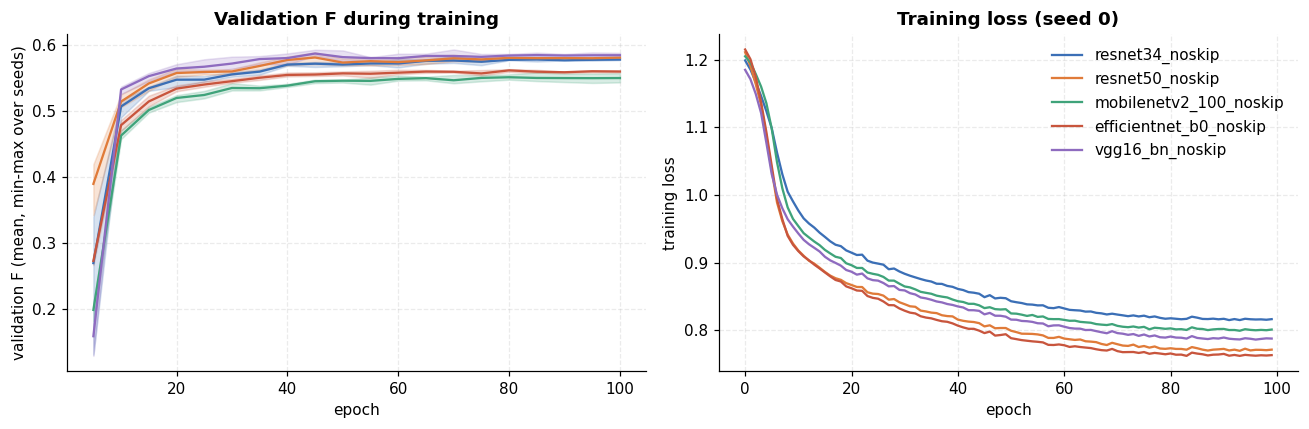

In [9]:
for b in BACKBONES:
    per_seed = pd.DataFrame(
        {"best epoch": [runs[b][s]["epoch"] for s in SEEDS], "threshold": [runs[b][s]["thr"] for s in SEEDS],
         "val F": [runs[b][s]["val_f"] for s in SEEDS], "test F": [runs[b][s]["test"][:, 2].mean() for s in SEEDS]},
        index=[f"seed {s}" for s in SEEDS])
    print(f"{run_name(b)}: per seed"); print(per_seed.round(3).to_string()); print()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for b in BACKBONES:
    ep = runs[b][SEEDS[0]]["hist"]["val_epoch"]
    vf = np.array([runs[b][s]["hist"]["val_f"] for s in SEEDS])
    line, = axes[0].plot(ep, vf.mean(0), label=run_name(b))
    axes[0].fill_between(ep, vf.min(0), vf.max(0), color=line.get_color(), alpha=0.2)
    axes[1].plot(runs[b][SEEDS[0]]["hist"]["loss"], label=run_name(b))
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("validation F (mean, min-max over seeds)"); axes[0].set_title("Validation F during training")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("training loss"); axes[1].set_title("Training loss (seed 0)")
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()

## 9 · Qualitative results
*Seed 0, first test images: image · human edges · Canny · each backbone, with per-image F*

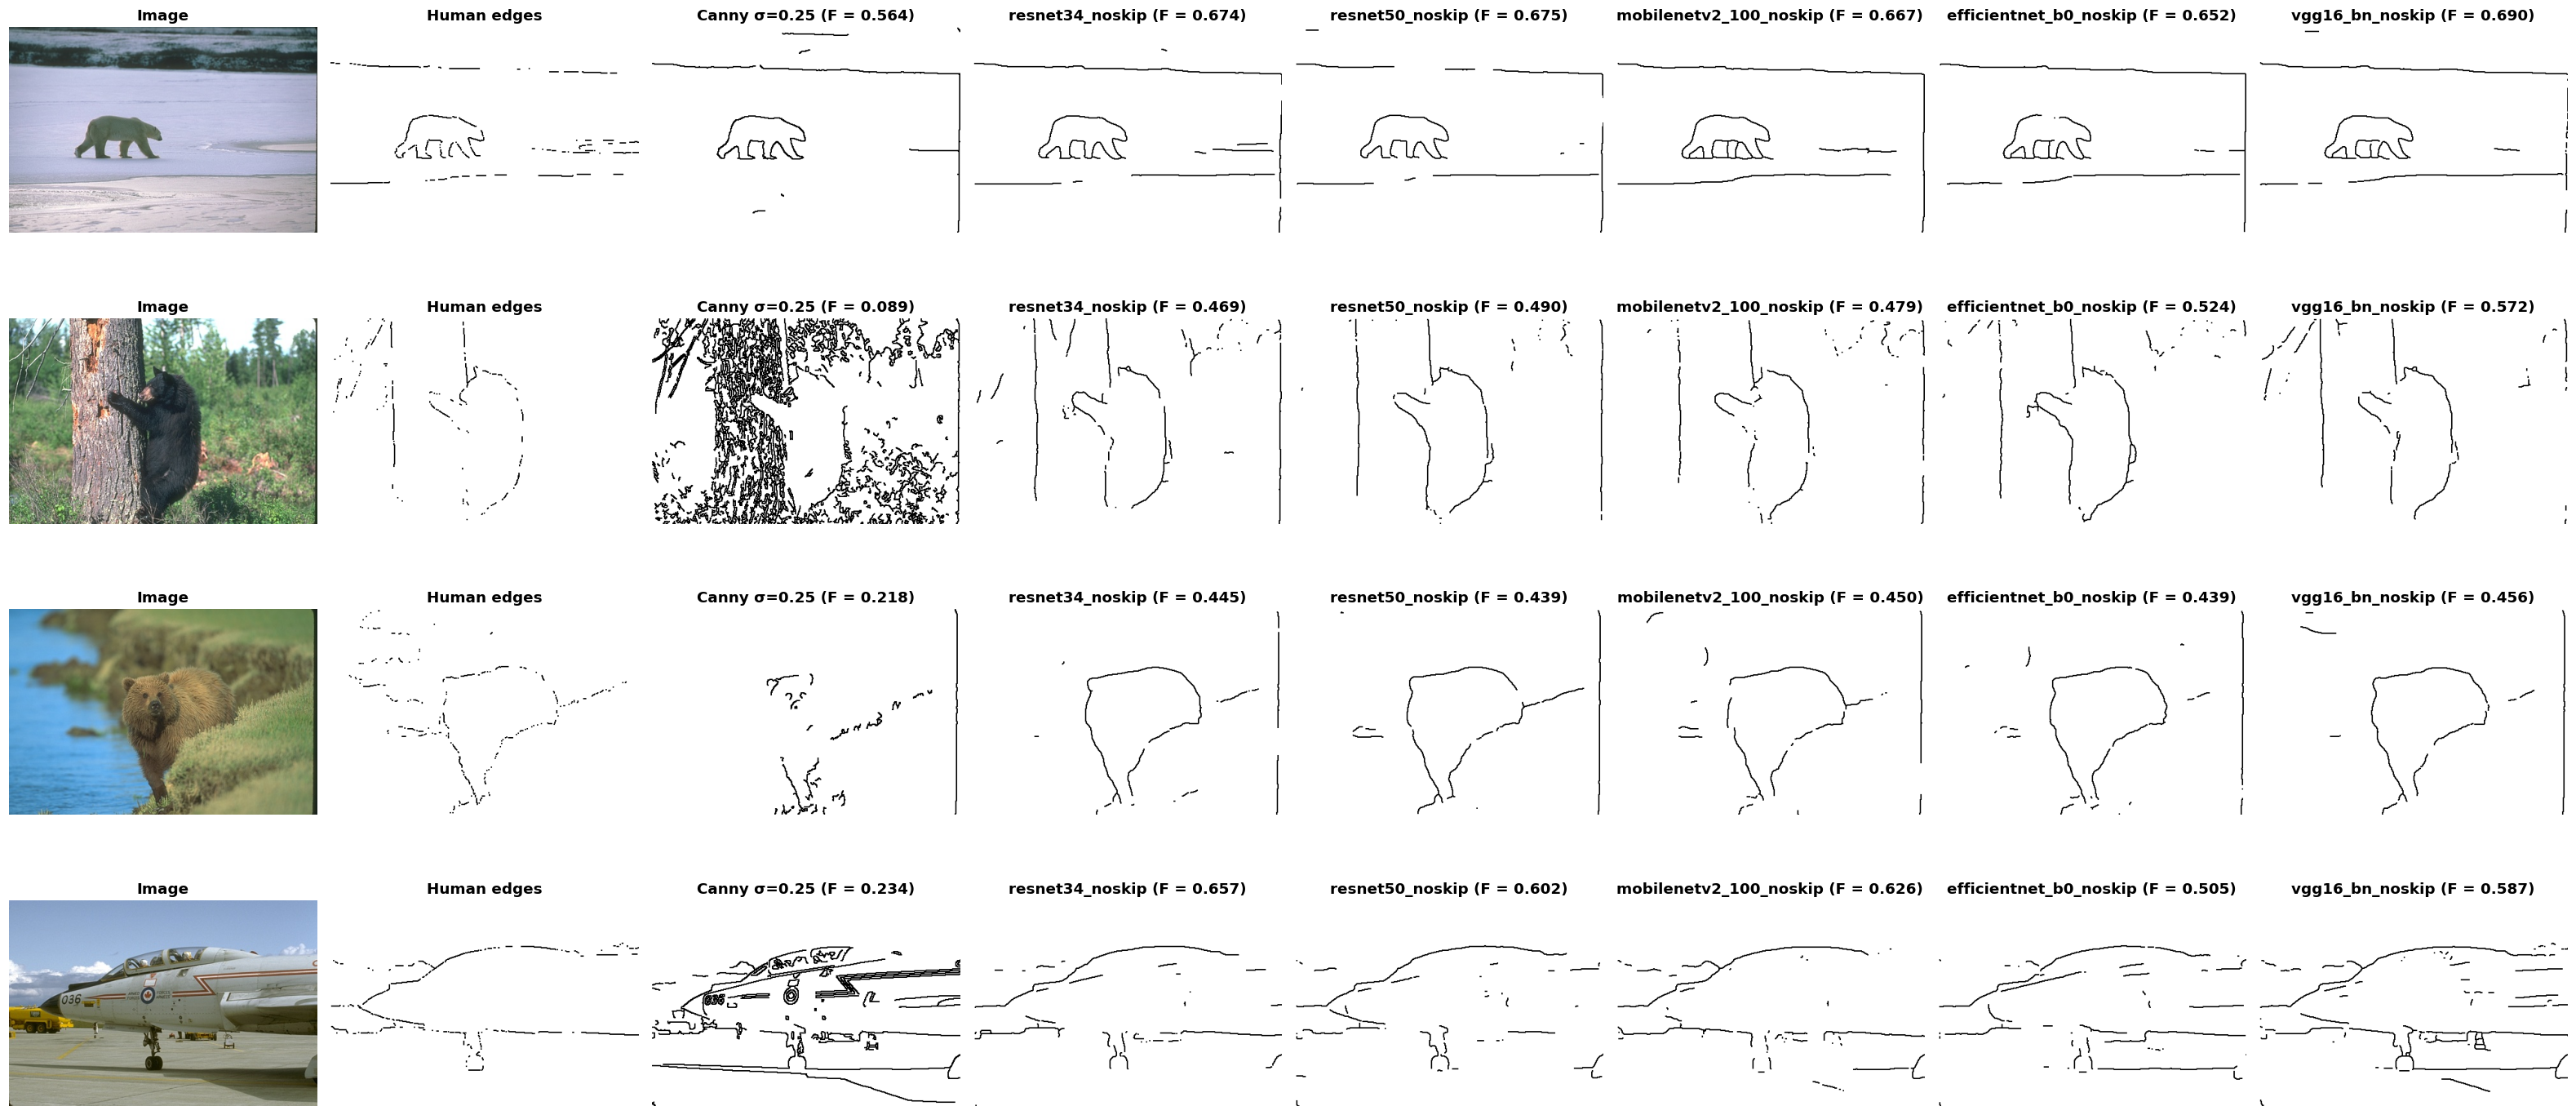

In [10]:
def paint(mask, thicken=True):
    m = mask.astype(np.uint8)
    if thicken:
        m = cv2.dilate(m, np.ones((2, 2), np.uint8))
    return np.where(m > 0, 0, 255).astype(np.uint8)

n_show = min(N_SHOW, len(test_names))
ncol = 3 + len(BACKBONES)
fig, axes = plt.subplots(n_show, ncol, figsize=(3.6 * ncol, 3.4 * n_show))
axes = np.atleast_2d(axes)
for r in range(n_show):
    img, canny, gt = data[test_names[r]]
    if ref_sigma is not None:
        canny_panel = (f"Canny σ={ref_sigma:g}", paint(canny[CANNY_SIGMAS.index(ref_sigma)]), canny_test[r, 2])
    else:
        canny_panel = ("No Canny", np.full(gt.shape, 255, np.uint8), None)
    panels = [("Image", img, None), ("Human edges", paint(gt), None), canny_panel]
    panels += [(run_name(b), paint(show[b]["preds"][r]), runs[b][SEEDS[0]]["test"][r, 2]) for b in BACKBONES]
    for ax, (title, im, f) in zip(axes[r], panels):
        ax.imshow(im, cmap="gray" if im.ndim == 2 else None, vmin=0, vmax=255 if im.ndim == 2 else None)
        ax.set_title(title if f is None else f"{title} (F = {f:.3f})")
        ax.axis("off")
fig.tight_layout()
plt.show()

## 10 · Final comparison
*Test F-score of every backbone*

Reads every `results_<run>.json` (per-image test precision / recall / F for every seed) and builds one table over the **200 test images**: Canny baseline and each backbone, mean ± std over seeds, plus parameters, GFLOPs and time per image. Earlier sessions added as a Kaggle dataset (under `/kaggle/input`) are included, so RGB-only and Canny runs can sit in the same table.

The cell also shows a paired comparison against a reference run (`REFERENCE`, default = best run) and a bar chart.

5 runs: efficientnet_b0_noskip, mobilenetv2_100_noskip, resnet34_noskip, resnet50_noskip, vgg16_bn_noskip

TEST SET: 200 images, mean over seeds
                    run        backbone                    input  seeds  precision  recall  test F  F std (seeds)  val F  params (M)  GFLOPs  ms/img
        vgg16_bn_noskip        vgg16_bn RGB + Canny (input only)      3      0.587   0.701   0.627          0.004  0.588      19.040 115.728  23.409
        resnet50_noskip        resnet50 RGB + Canny (input only)      3      0.602   0.645   0.612          0.003  0.584      32.538  51.359  16.836
        resnet34_noskip        resnet34 RGB + Canny (input only)      3      0.600   0.643   0.610          0.001  0.580      24.453  38.147  13.381
 efficientnet_b0_noskip efficientnet_b0 RGB + Canny (input only)      3      0.571   0.654   0.598          0.002  0.563       5.837  13.934  16.856
 mobilenetv2_100_noskip mobilenetv2_100 RGB + Canny (input only)      3      0.577   0.622   0.587          0.

run,backbone,input,seeds,precision,recall,test F,F std (seeds),val F,params (M),GFLOPs,ms/img
vgg16_bn_noskip,vgg16_bn,RGB + Canny (input only),3,0.587,0.701,0.627,0.004,0.588,19.0,116,23
resnet50_noskip,resnet50,RGB + Canny (input only),3,0.602,0.645,0.612,0.003,0.584,32.5,51,17
resnet34_noskip,resnet34,RGB + Canny (input only),3,0.600,0.643,0.610,0.001,0.580,24.5,38,13
efficientnet_b0_noskip,efficientnet_b0,RGB + Canny (input only),3,0.571,0.654,0.598,0.002,0.563,5.8,14,17
mobilenetv2_100_noskip,mobilenetv2_100,RGB + Canny (input only),3,0.577,0.622,0.587,0.008,0.552,4.0,13,12
Canny (best sigma=0.25),-,classical,0,0.165,0.823,0.250,–,–,–,–,–



PAIRED DIFFERENCE vs vgg16_bn_noskip (same test images)
                   run  mean dF vs vgg16_bn_noskip  +/- s.e.m. images improved
efficientnet_b0_noskip                      -0.029       0.003          42/200
mobilenetv2_100_noskip                      -0.041       0.003          30/200
       resnet34_noskip                      -0.017       0.003          58/200
       resnet50_noskip                      -0.015       0.003          65/200


run,mean dF vs vgg16_bn_noskip,+/- s.e.m.,images improved
efficientnet_b0_noskip,-0.029,0.003,42/200
mobilenetv2_100_noskip,-0.041,0.003,30/200
resnet34_noskip,-0.017,0.003,58/200
resnet50_noskip,-0.015,0.003,65/200


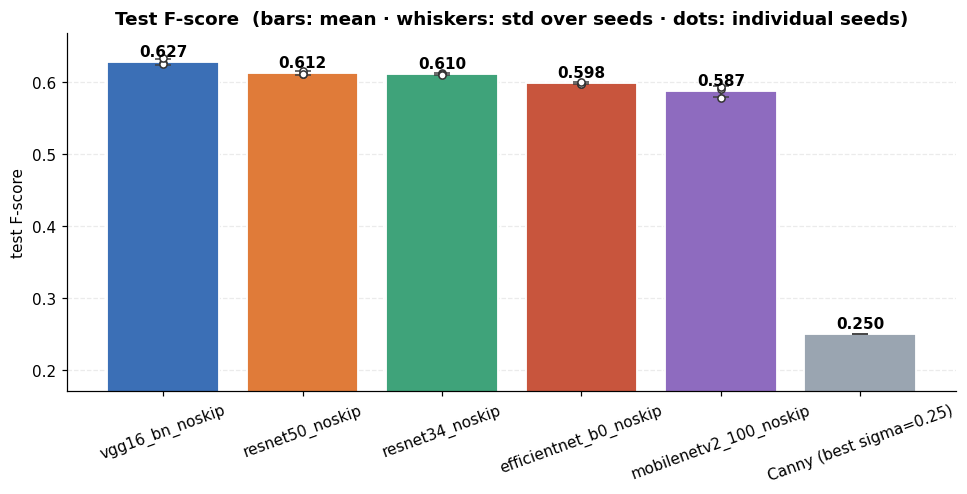

In [11]:
import glob, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESULT_GLOBS = ["/kaggle/input/*/results_*.json", "/kaggle/input/*/*/results_*.json", "/kaggle/working/results_*.json"]
REFERENCE = None        # run name for the paired comparison (e.g. "resnet34"); None = best run

files = sorted({f for g in RESULT_GLOBS for f in glob.glob(g)})
assert files, "no results_*.json found: run at least one backbone first"
res = {}
for f in files:                      # later files (/kaggle/working) overwrite earlier ones with the same run name
    r = json.load(open(f))
    res[r["run"]] = r
print(f"{len(res)} runs: {', '.join(res)}")

def arr(r):                          # (seeds, test images, 3) = precision, recall, F
    return np.array([r["seeds"][s]["test"] for s in sorted(r["seeds"], key=int)])

def mode(r):
    if not r["canny_sigmas"]:
        return "RGB only"
    return "RGB + Canny (input + skip)" if r["canny_skip"] else "RGB + Canny (input only)"

rows, Fimg = [], {}
for name, r in res.items():
    a = arr(r)
    f_seed = a[:, :, 2].mean(1)
    Fimg[name] = a[:, :, 2]
    cxi = r.get("complexity") or {}
    rows.append({"run": name, "backbone": r["backbone"], "input": mode(r), "seeds": len(f_seed),
                 "precision": a[:, :, 0].mean(), "recall": a[:, :, 1].mean(),
                 "test F": f_seed.mean(), "F std (seeds)": f_seed.std(ddof=1) if len(f_seed) > 1 else np.nan,
                 "val F": np.mean([r["seeds"][s]["val_f"] for s in r["seeds"]]),
                 "params (M)": cxi.get("params_M"), "GFLOPs": cxi.get("gflops"), "ms/img": cxi.get("ms_per_image")})

seen = set()
for name, r in res.items():          # Canny baseline (no training): one row per set of Canny levels
    key = tuple(r["canny_sigmas"])
    if r.get("canny_test") is not None and key not in seen:
        seen.add(key)
        c = np.array(r["canny_test"])
        rows.append({"run": f"Canny (best sigma={r['canny_ref_sigma']:g})", "backbone": "-", "input": "classical", "seeds": 0,
                     "precision": c[:, 0].mean(), "recall": c[:, 1].mean(), "test F": c[:, 2].mean()})

table = pd.DataFrame(rows).sort_values("test F", ascending=False).reset_index(drop=True)
pd.set_option("display.width", 250, "display.max_columns", 20)
print(f"\nTEST SET: {len(next(iter(Fimg.values()))[0])} images, mean over seeds")
print(table.round(3).to_string(index=False))
fmt = {c: "{:.3f}" for c in ["precision", "recall", "test F", "F std (seeds)", "val F"]}
fmt.update({"params (M)": "{:.1f}", "GFLOPs": "{:.0f}", "ms/img": "{:.0f}", "seeds": "{:d}"})
styled = (table.style.hide(axis="index").format(fmt, na_rep="–")
          .background_gradient(subset=["test F"], cmap="YlGn", vmin=table["test F"].min() - 0.05)
          .background_gradient(subset=["precision"], cmap="Blues", vmin=0)
          .background_gradient(subset=["recall"], cmap="Oranges", vmin=0)
          .highlight_max(subset=["test F"], props="font-weight: bold; border: 2px solid #3FA37A;")
          .set_properties(**{"text-align": "center", "padding": "6px 12px"})
          .set_properties(subset=["run"], **{"text-align": "left", "font-weight": "600"})
          .set_caption("Test F-score per backbone (200 test images, mean over seeds)")
          .set_table_styles([
              {"selector": "caption", "props": "caption-side: top; font-size: 1.15em; font-weight: bold; padding: 8px 0; text-align: left;"},
              {"selector": "th", "props": "background-color: #2F3E55; color: white; text-align: center; padding: 8px 12px;"},
              {"selector": "td", "props": "border-bottom: 1px solid #e3e6eb;"}]))
display(styled)

# paired comparison against a reference run (per-image F averaged over seeds)
ref = REFERENCE if REFERENCE in Fimg else max(Fimg, key=lambda n: Fimg[n].mean())
pr = []
for n in Fimg:
    if n != ref:
        d = Fimg[n].mean(0) - Fimg[ref].mean(0)
        pr.append({"run": n, f"mean dF vs {ref}": d.mean(), "+/- s.e.m.": d.std(ddof=1) / np.sqrt(len(d)),
                   "images improved": f"{int((d > 0).sum())}/{len(d)}"})
if pr:
    pt = pd.DataFrame(pr)
    print(f"\nPAIRED DIFFERENCE vs {ref} (same test images)")
    print(pt.round(3).to_string(index=False))
    dcol = [c for c in pt.columns if c.startswith("mean dF")][0]
display(pt.style.hide(axis="index").format({dcol: "{:+.3f}", "+/- s.e.m.": "{:.3f}"})
        .background_gradient(subset=[dcol], cmap="RdYlGn", vmin=-0.05, vmax=0.05)
        .set_properties(**{"text-align": "center", "padding": "6px 12px"})
        .set_caption(f"Paired difference vs {ref} (same test images)")
        .set_table_styles([
            {"selector": "caption", "props": "caption-side: top; font-size: 1.1em; font-weight: bold; padding: 8px 0; text-align: left;"},
            {"selector": "th", "props": "background-color: #2F3E55; color: white; text-align: center; padding: 8px 12px;"},
            {"selector": "td", "props": "border-bottom: 1px solid #e3e6eb;"}]))

order = list(table["run"])
colors = ["#9AA5B1" if n not in Fimg else PALETTE[k % len(PALETTE)] for k, n in enumerate(order)]
fig, ax = plt.subplots(figsize=(max(6, 1.5 * len(table)), 4.6))
bars = ax.bar(order, table["test F"], yerr=table["F std (seeds)"].fillna(0), color=colors, edgecolor="white",
              linewidth=1.2, capsize=5, error_kw={"ecolor": "0.25", "elinewidth": 1.2}, zorder=2)
for i, n in enumerate(order):
    if n in Fimg:
        ax.scatter(np.full(len(Fimg[n]), i), Fimg[n].mean(1), color="white", edgecolor="0.2", s=22, zorder=4)
for b_, v in zip(bars, table["test F"]):
    ax.text(b_.get_x() + b_.get_width() / 2, v + 0.004, f"{v:.3f}", ha="center", va="bottom", fontsize=10, fontweight="bold", zorder=5)
ax.set_ylim(max(0, table["test F"].min() - 0.08), table["test F"].max() + 0.04)
ax.set_ylabel("test F-score")
ax.grid(axis="x", visible=False)
ax.tick_params(axis="x", rotation=20)
ax.set_title("Test F-score  (bars: mean · whiskers: std over seeds · dots: individual seeds)")
fig.tight_layout()
plt.show()


## 11 · Inference time on the test set
*Wall-clock time of each backbone over the 200 test images*

Each model is built fresh (speed does not depend on the trained weights), warmed up, then timed over the whole test set, one image at a time, with GPU synchronisation. Includes padding to a multiple of 32 and the forward pass; excludes thresholding, thinning and the F-score.

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.
Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


backbone,total (s),std (s),ms / image,images / s
resnet34_noskip,2.58,0.03,12.9,77.5
mobilenetv2_100_noskip,2.91,0.06,14.6,68.7
resnet50_noskip,3.52,0.01,17.6,56.8
efficientnet_b0_noskip,3.79,0.01,18.9,52.8
vgg16_bn_noskip,4.03,0.01,20.2,49.6


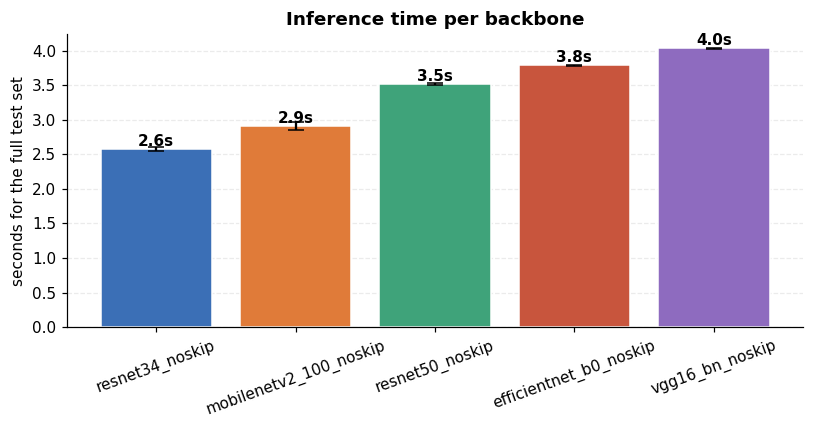

In [12]:
@torch.no_grad()
def time_inference(m, items, warmup=5, repeats=3):
    m.eval()
    def run():
        for x, _ in items:
            h, w = x.shape[-2:]
            xp = F.pad(x[None].to(device), (0, (-w) % 32, 0, (-h) % 32), mode="reflect")
            m(xp)
    for x, _ in items[:warmup]:
        h, w = x.shape[-2:]
        m(F.pad(x[None].to(device), (0, (-w) % 32, 0, (-h) % 32), mode="reflect"))
    times = []
    for _ in range(repeats):
        if device.type == "cuda": torch.cuda.synchronize()
        t0 = time.time()
        run()
        if device.type == "cuda": torch.cuda.synchronize()
        times.append(time.time() - t0)
    return times

rows = []
for b in BACKBONES:
    m = build_model(b).to(device)
    ts = time_inference(m, test_items)
    rows.append({"backbone": run_name(b), "total (s)": np.mean(ts), "std (s)": np.std(ts, ddof=1) if len(ts) > 1 else np.nan,
                 "ms / image": np.mean(ts) / len(test_items) * 1000, "images / s": len(test_items) / np.mean(ts)})
    del m
    torch.cuda.empty_cache()

time_table = pd.DataFrame(rows).sort_values("total (s)").reset_index(drop=True)
display(time_table.style.hide(axis="index")
        .format({"total (s)": "{:.2f}", "std (s)": "{:.2f}", "ms / image": "{:.1f}", "images / s": "{:.1f}"}, na_rep="–")
        .background_gradient(subset=["ms / image"], cmap="YlOrRd")
        .background_gradient(subset=["images / s"], cmap="YlGn")
        .set_properties(**{"text-align": "center", "padding": "6px 12px"})
        .set_properties(subset=["backbone"], **{"text-align": "left", "font-weight": "600"})
        .set_caption(f"Inference time on {len(test_items)} test images ({gpu_names})")
        .set_table_styles([
            {"selector": "caption", "props": "caption-side: top; font-size: 1.15em; font-weight: bold; padding: 8px 0; text-align: left;"},
            {"selector": "th", "props": "background-color: #2F3E55; color: white; text-align: center; padding: 8px 12px;"},
            {"selector": "td", "props": "border-bottom: 1px solid #e3e6eb;"}]))

fig, ax = plt.subplots(figsize=(max(5, 1.5 * len(time_table)), 4))
bars = ax.bar(time_table["backbone"], time_table["total (s)"], yerr=time_table["std (s)"].fillna(0),
              color=PALETTE[:len(time_table)], edgecolor="white", capsize=5, zorder=2)
for b_, v in zip(bars, time_table["total (s)"]):
    ax.text(b_.get_x() + b_.get_width() / 2, v, f"{v:.1f}s", ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_ylabel("seconds for the full test set")
ax.set_title("Inference time per backbone")
ax.grid(axis="x", visible=False)
ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
plt.show()